# Example: Adaptive Drug Dosing with Q-Learning
Chemotherapy treats cancer with drugs that kill fast-dividing cells. The drug shrinks a tumor, a mass of cancer cells, but it also damages healthy tissue. This damage, called toxicity, builds up with each dose and clears only slowly between doses. In this example, we treat a course of chemotherapy as a Markov decision process, in which each treatment cycle we choose a dose, and learn a dosing policy with Q-learning.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Formulate a treatment as a Markov decision process:__ The state of the patient is the size of the tumor and the level of toxicity, and each action is a drug dose that changes both in the next cycle. We'll build this environment and see why no fixed dose cures the patient.
> * __Compute the optimal dosing policy by value iteration:__ When we know the rules of the treatment, value iteration computes the best dose in every patient state. We'll use this optimal policy as the benchmark for the learned one.
> * __Learn a dosing policy with Q-learning:__ A Q-learning agent learns from simulated treatment cycles alone, without access to the rules that produced them. We'll train an agent and compare its doses with the optimal ones, state by state and over a full treatment.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we load the local [`Include.jl`](Include.jl) setup file and its required packages.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates [`Include.jl`](Include.jl) in the notebook's global scope. The setup file activates the course project, defines local paths, and loads the course package, this example's code in [src/Dosing.jl](src/Dosing.jl), and the packages used here.

Let's set up our code environment:

In [1]:
# Load packages and paths -
include(joinpath(@__DIR__, "Include.jl")); # @__DIR__ locates this notebook's setup file

# Choose one theme; after changing it, rerun this cell and the plotting cells -
theme(:default)   # light background
# theme(:dark)   # dark background

In addition to the Julia standard libraries, we use [the `VLDataScienceMachineLearningPackage.jl` package](https://github.com/varnerlab/VLDataScienceMachineLearningPackage.jl) for the Q-learning agent and the policy, [Plots.jl](https://docs.juliaplots.org/stable/) for the figures, and [DataFrames.jl](https://dataframes.juliadata.org/stable/) with [PrettyTables.jl](https://ronisbr.github.io/PrettyTables.jl/stable/) for the tables. See [the package documentation](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/) and the [Julia documentation](https://docs.julialang.org/en/v1/) for the functions and types used here.
___

## Task 1: Build the dosing environment
In this task, we describe the patient as a Markov decision process and build it. The patient state has two variables: the tumor burden $B\in[0,1]$, the size of the tumor scaled so that 1 is the largest it can grow, and the toxicity $Z\in[0,1]$. Each cycle $t$, we choose a dose $u_{t}\in\{0,\tfrac{1}{3},\tfrac{2}{3},1\}$, i.e., none, low, medium, or high. The state then changes according to two equations:

$$
\begin{align*}
B_{t+1} &= B_{t} + \underbrace{g\,B_{t}\,(1 - B_{t})}_{\text{tumor growth}} - \underbrace{k\,u_{t}\,B_{t}}_{\text{tumor killed}}\\
Z_{t+1} &= Z_{t} + \underbrace{b\,u_{t}}_{\text{toxicity added}} - \underbrace{c\,Z_{t}}_{\text{toxicity cleared}}
\end{align*}
$$

where $g$ is the tumor growth rate, $k$ is the fraction of the tumor a full dose kills, $b$ is the toxicity a full dose adds, and $c$ is the fraction of the toxicity the body clears each cycle.

The growth term is logistic: the tumor grows fastest at medium size and stops growing as it approaches its largest size. We clip each new value to lie between 0 and 1 and round it to the nearest of 41 evenly spaced levels, so the set of states is finite. Two kinds of states are absorbing, and the treatment ends when the patient enters one:
* __Cure__: the tumor burden falls to $B\leq B_{\text{cure}}$, which earns the reward $r_{\text{cure}}>0$.
* __Toxic death__: the toxicity reaches $Z\geq Z_{\text{lethal}}$, which earns the reward $r_{\text{dead}}<0$. A state that meets both conditions counts as a toxic death.

Every other cycle earns a penalty that grows with the tumor, the toxicity, and the dose:

$$
\begin{equation*}
r = -\left(w_{B}\,B_{t+1} + w_{Z}\,Z_{t+1} + w_{u}\,u_{t}\right)
\end{equation*}
$$

where $w_{B}$, $w_{Z}$, and $w_{u}$ are nonnegative weights. Because a dose now raises the toxicity of later cycles, the best dose depends on the rest of the treatment, not just the current cycle.

We encode the environment with [the `MyAdaptiveDosingModel` type](src/Dosing.jl), which stores the grid of patient states, the doses, and the parameters. [The `build(...)` function](src/Dosing.jl) takes the parameters in a `NamedTuple` and numbers the grid states $1,2,\dots,41^{2}$.

Let's build the environment and save it in the `env::MyAdaptiveDosingModel` variable:

In [2]:
env = build(MyAdaptiveDosingModel, (
    nlevels = 41, # 41 levels on each axis: B and Z take the values 0, 0.025, ..., 1
    doses = [0.0, 1/3, 2/3, 1.0], # the doses of the four actions: none, low, medium, high
    g = 0.15, # tumor growth rate per cycle
    k = 0.35, # fraction of the tumor a full dose kills per cycle
    b = 0.50, # toxicity a full dose adds per cycle
    c = 0.35, # fraction of the toxicity cleared per cycle
    Bcure = 0.10, # the patient is cured when B ≤ 0.10
    Zlethal = 0.90, # the patient dies of toxicity when Z ≥ 0.90
    wB = 1.0, # weight of the tumor burden in the penalty
    wZ = 1.0, # weight of the toxicity in the penalty
    wu = 0.10, # weight of the dose in the penalty
    rcure = 60.0, # reward for a cure
    rdead = -60.0, # reward for a toxic death
));
nstates = env.nlevels^2; # the number of states, 41 × 41
nactions = length(env.doses); # the number of actions, one per dose

Every treatment in this example starts from a large tumor and no toxicity, $(B_{0}, Z_{0}) = (0.90, 0)$. [The `stateindex(...)` function](src/Dosing.jl) returns the grid state nearest a patient state, and [the `decode(...)` function](src/Dosing.jl) returns the patient state of a grid state:

In [3]:
s₀ = stateindex(env, 0.90, 0.0); # the starting state: a large tumor and no toxicity
decode(env, s₀) # check: (B, Z) of the starting state

(0.9, 0.0)

### Why a fixed dose fails
Before we compute a policy, let's try the four fixed doses. A fixed dose is a policy that chooses the same action in every state. [The `simulate(...)` function](src/Dosing.jl) follows a policy from a starting state until the patient is cured, dies of toxicity, or 100 cycles pass, which we call a timeout.

Let's follow each fixed dose from the starting state:

In [4]:
let
    df = DataFrame(); # one row per fixed dose
    labels = ["none", "low", "medium", "high"];
    for a ∈ 1:nactions
        π_fixed = fill(a, nstates); # the same action a in every state
        result = simulate(env, π_fixed, s₀);
        push!(df, (schedule = labels[a], dose = round(env.doses[a], digits = 2),
            outcome = String(result.outcome), cycles = result.steps));
    end
    pretty_table(df; backend = :text,
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 ---------- --------- --------- --------
  schedule      dose   outcome   cycles 
    String   Float64    String    Int64 
 ---------- --------- --------- --------
      none       0.0   timeout      100
       low      0.33   timeout      100
    medium      0.67      dead        7
      high       1.0      dead        3
 ---------- --------- --------- --------


No fixed dose cures the patient. With no dose or the low dose, the tumor never shrinks to the cure level, and the medium and high doses raise the toxicity to the lethal level. To cure the patient, the dose must change with the state.
___

## Task 2: The optimal policy by value iteration
In this task, we compute the optimal policy with value iteration. We know the dynamics here, because [the `world(...)` function](src/Dosing.jl) computes them, so the optimal policy is our benchmark for the learned one. Each action has a single next state $s^{\prime}$, so the Bellman backup of a state needs no sum over next states:

$$
\begin{equation*}
U(s)\gets\max_{a\in\mathcal{A}}\left(R(s,a) + \gamma\,U(s^{\prime})\right)
\end{equation*}
$$

where $R(s,a)$ is the reward of action $a$ in state $s$ and $\gamma$ is the discount factor.

[The `solve(...)` function](src/Dosing.jl) for the dosing environment applies this backup to every state until the values stop changing, and returns the optimal action-value table $Q^{*}$, one row per state and one column per action. [The `policy(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/mdp/#VLDataScienceMachineLearningPackage.policy-Tuple{Matrix{Float64}}) reads the best action from each row.

Let's compute the optimal action values and the optimal policy:

In [5]:
γ = 0.95; # discount factor
Qstar = solve(env; γ = γ); # value iteration: the optimal action-value table
π_star = policy(Qstar); # the optimal policy: the best action in each state

Let's follow the optimal policy from the starting state and print the dose it gives each cycle:

In [6]:
optimal = simulate(env, π_star, s₀); # follow the optimal policy from the large tumor
println("Outcome: ", optimal.outcome, " after ", optimal.steps, " cycles");
println("Doses: ", round.(optimal.dose, digits = 2));

Outcome: cured after 13 cycles
Doses: 

[1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.67, 0.33, 0.67, 0.67, 0.67, 0.0]


The optimal policy cures the patient. It alternates high doses, which shrink the tumor, with rest cycles at dose 0, which let the toxicity clear before the next high dose, and it finishes with medium and low doses. We call this a pulse-and-rest schedule. A fixed dose cannot produce it, because the dose depends on the patient's state.
___

## Task 3: Learn a dosing policy with Q-learning
In this task, we suppose we do not know the dynamics. The agent can only give a dose and observe the reward and the next state that [the `world(...)` function](src/Dosing.jl) returns, just as it would from the records of real treatments. It never uses the function to look ahead.

We store the agent in a `MyQLearningAgentModel` from the course package, which holds the states, the actions, a learning rate $\alpha$, the discount factor $\gamma$, and the table $Q$. [The `build(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/factory/) makes the agent, and [the `solve(...)` function](src/Dosing.jl) for an agent and the dosing environment trains it.

> __Training:__ Each episode starts from a random state that is not absorbing and runs until the patient is cured, dies, or 80 cycles pass. The learning rate of the $n$-th update of a pair $(s,a)$ is $1/n$, as in the convergence conditions of the [lecture](CHEME-5800-L12a-Lecture-QLearning-Fall-2026.ipynb). The exploration probability $\epsilon$ falls from 1 to 0.05 over the first 70 percent of the episodes and then stays at 0.05.

The seed fixes the random numbers, so training again with the same seed gives the same agent. Let's build the agent, train it for 200,000 episodes, and read its policy:

In [7]:
agent = build(MyQLearningAgentModel, (
    states = collect(1:nstates), # the states 1, 2, ..., nstates
    actions = collect(1:nactions), # the actions 1, 2, 3, 4
    α = 0.1, # learning rate field (solve(...) below uses 1/n instead)
    γ = γ, # the same discount factor as value iteration
    Q = zeros(nstates, nactions), # the table starts at zero
));
agent = solve(agent, env; episodes = 200_000, maxsteps = 80, seed = 1234); # model-free training
π_q = policy(agent.Q); # the learned policy: the best action in each row of the learned table

Let's follow the learned policy from the same starting state:

In [8]:
learned = simulate(env, π_q, s₀); # follow the learned policy from the large tumor
println("Outcome: ", learned.outcome, " after ", learned.steps, " cycles");
println("Doses: ", round.(learned.dose, digits = 2));

Outcome: cured after 13 cycles
Doses: [1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.67, 0.33, 0.67, 0.67, 0.67, 0.0]


The learned policy gives the same doses as the optimal policy, so the agent found the pulse-and-rest schedule from simulated treatment cycles alone.

### Benchmark against the optimum
A single treatment checks only the states it passes through. Let's compare the two policies on every state the optimal policy visits from starting tumor burdens $B_{0}=0.10, 0.15,\dots,0.95$ with no toxicity. For each visited state where the two actions differ, the value lost by the learned action is $Q^{*}(s,\pi^{*}(s)) - Q^{*}(s,\pi_{q}(s))$, where $\pi^{*}$ is the optimal policy and $\pi_{q}$ is the learned policy.

In [9]:
let
    # the states the optimal policy visits, from starting tumor burdens 0.10, 0.15, ..., 0.95 -
    visited = Set{Int64}();
    for B₀ ∈ 0.10:0.05:0.95
        s = stateindex(env, B₀, 0.0);
        for t ∈ 1:100 # at most 100 cycles
            if (isterminal(env, s) == true)
                break; # cured or dead: the treatment has ended
            end
            push!(visited, s);
            (s, _) = world(env, s, π_star[s]); # the _ discards the reward
        end
    end

    # compare the two policies on the visited states -
    number_same = 0; # states where the two policies choose the same action
    largest_loss = 0.0; # the most value lost where they differ
    smallest_value = Inf; # the smallest optimal value of a visited state
    largest_value = -Inf; # the largest optimal value of a visited state
    for s ∈ visited
        value = Qstar[s, π_star[s]]; # the optimal value of state s
        smallest_value = min(smallest_value, value);
        largest_value = max(largest_value, value);
        if (π_q[s] == π_star[s])
            number_same = number_same + 1;
        else
            loss = value - Qstar[s, π_q[s]]; # the value lost by the learned action
            largest_loss = max(largest_loss, loss);
        end
    end

    # show -
    println("Visited states: ", length(visited));
    println("Same action: ", number_same, " (", round(100*number_same/length(visited), digits = 1), "%)");
    println("Optimal values of the visited states: ", round(smallest_value, digits = 1), " to ", round(largest_value, digits = 1));
    println("Largest value lost by a different action: ", round(largest_loss, digits = 2));
end

Visited states: 71
Same action: 53 (74.6%)
Optimal values of the visited states: 20.2 to 60.0
Largest value lost by a different action: 3.13


The two policies choose the same action in about three quarters of the visited states. In the rest, the learned action is close in value to the optimal one: it gives up at most about 3 units of discounted reward, in states whose optimal values lie between about 20 and 60. These states are visited less often during training, and they have two doses of similar value.

Let's also follow both policies from four starting tumor burdens:

In [10]:
let
    df = DataFrame(); # one row per starting tumor burden
    for B₀ ∈ [0.30, 0.50, 0.70, 0.90]
        s = stateindex(env, B₀, 0.0); # this start, with no toxicity
        a = simulate(env, π_star, s); # the optimal policy
        b = simulate(env, π_q, s); # the learned policy
        push!(df, (B₀ = B₀, optimal = String(a.outcome), optimal_cycles = a.steps,
            learned = String(b.outcome), learned_cycles = b.steps));
    end
    pretty_table(df; backend = :text, display_size = (-1, -1),
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 --------- --------- ---------------- --------- ----------------
       B₀   optimal   optimal_cycles   learned   learned_cycles 
  Float64    String            Int64    String            Int64 
 --------- --------- ---------------- --------- ----------------
      0.3     cured                6     cured                7
      0.5     cured                9     cured                9
      0.7     cured               12     cured               13
      0.9     cured               13     cured               13
 --------- --------- ---------------- --------- ----------------


Both policies cure the patient from every start, and the learned policy takes at most one more cycle than the optimal one.

### Visualize the policy and a treatment
Finally, let's draw the optimal policy as a heatmap of the dose it gives in each patient state $(B, Z)$, with the treatment from the starting state drawn on top. The absorbing states are left blank.

Let's draw the heatmap:

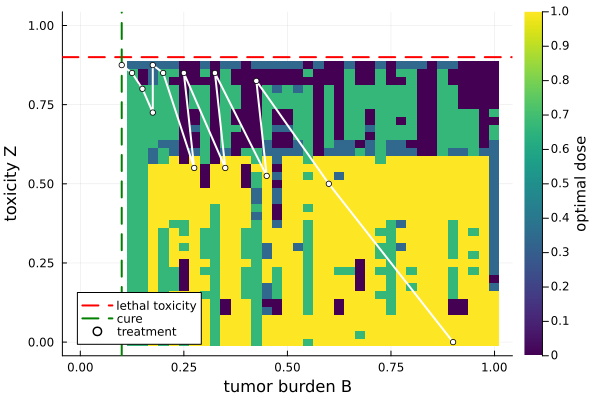

In [11]:
let
    # the levels of the grid, 0, 0.025, ..., 1 -
    levels = range(0.0, stop = 1.0, length = env.nlevels) |> collect;

    # the optimal dose in each state; NaN (blank) in the absorbing states -
    M = fill(NaN, env.nlevels, env.nlevels); # rows are toxicity levels, columns are tumor levels
    for iB ∈ 1:env.nlevels
        for iZ ∈ 1:env.nlevels
            s = env.states[(iB, iZ)];
            if (isterminal(env, s) == false)
                M[iZ, iB] = env.doses[π_star[s]];
            end
        end
    end

    # draw the policy, the thresholds, and the treatment -
    p = heatmap(levels, levels, M, c = :viridis, colorbar_title = "optimal dose",
        xlabel = "tumor burden B", ylabel = "toxicity Z", legend = :bottomleft);
    hline!(p, [env.Zlethal], color = :red, ls = :dash, lw = 2, label = "lethal toxicity");
    vline!(p, [env.Bcure], color = :green, ls = :dash, lw = 2, label = "cure");
    plot!(p, optimal.B, optimal.Z, lw = 2, c = :white, marker = :circle, ms = 3, label = "treatment");
    p
end

The treatment starts at the bottom right and moves left toward the cure line. Each high dose pushes the toxicity up toward the lethal line, and each rest cycle lets it fall before the next dose.

Let's draw the same treatment over time:

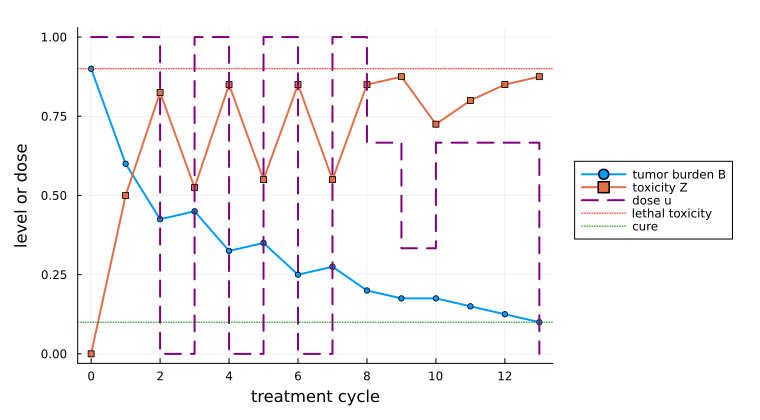

In [12]:
let
    cycles = range(0, stop = length(optimal.B) - 1, step = 1) |> collect; # the cycle numbers 0, 1, 2, ...
    p = plot(cycles, optimal.B, lw = 2, marker = :circle, ms = 3, label = "tumor burden B",
        xlabel = "treatment cycle", ylabel = "level or dose", legend = :outerright, size = (760, 420), margin = 5Plots.mm);
    plot!(p, cycles, optimal.Z, lw = 2, marker = :square, ms = 3, label = "toxicity Z");
    plot!(p, cycles, optimal.dose, seriestype = :steppost, lw = 2, ls = :dash, c = :purple, label = "dose u");
    hline!(p, [env.Zlethal], color = :red, ls = :dot, label = "lethal toxicity");
    hline!(p, [env.Bcure], color = :green, ls = :dot, label = "cure");
    p
end

The tumor burden falls with each high dose and grows back a little during each rest, while the toxicity rises and falls in a sawtooth that stays just below the lethal level.
___

## Summary
In this example, we treated a course of chemotherapy as a Markov decision process, computed the optimal dosing policy with value iteration, and learned a dosing policy with Q-learning.

> __Key Takeaways:__
>
> * __A dose now changes the patient later:__ Each dose shrinks the tumor but raises the toxicity of the cycles that follow, so no fixed dose cures the patient. The best dose depends on the rest of the treatment, which makes dosing a sequential decision problem.
>
> * __The optimal policy pulses and rests:__ Value iteration, using the known dynamics, found a schedule that alternates high doses with rest cycles so the toxicity can clear before the next dose. The schedule keeps the toxicity just below the lethal level while the tumor shrinks to the cure level.
>
> * __Q-learning recovers the optimal treatment from experience:__ Trained only on simulated treatment cycles, the agent gave the same doses as the optimal policy from the large starting tumor. Where the two policies differ, the learned dose is close in value to the optimal one.

When we know the rules of a system, value iteration gives the optimal policy; when we do not, Q-learning can learn it from experience alone.
___